# Práctica 6. Juegos clásicos: misioneros y caníbales, y gato con minimax

**Asignatura:** Inteligencia Artificial
**Unidad:** 2. Resolución de problemas por métodos de búsqueda

## Objetivo

Representar un problema clásico como espacio de estados, resolverlo con búsqueda y programar un jugador óptimo de gato mediante minimax y poda alfa-beta.

## Partes de la práctica

1. Misioneros y caníbales mediante búsqueda en anchura (BFS).
2. Gato mediante minimax y minimax con poda alfa-beta.

## Estados inicial y meta

In [1]:
# ---------------------------------------------------------
# PARTE A: MISIONEROS Y CANÍBALES
# ---------------------------------------------------------
# Cada estado se representa mediante una tupla:
#
# (m, c, b)
#
# m = número de misioneros en la orilla izquierda.
# c = número de caníbales en la orilla izquierda.
# b = posición de la barca:
#
#     0 -> orilla izquierda
#     1 -> orilla derecha
# ---------------------------------------------------------

# Al inicio, los 3 misioneros y los 3 caníbales
# se encuentran en la orilla izquierda.
estado_inicial_mc = (3, 3, 0)

# La meta consiste en trasladar a todos hacia
# la orilla derecha.
estado_meta_mc = (0, 0, 1)

# Mostramos ambos estados para comprobarlos.
print("Estado inicial:", estado_inicial_mc)
print("Estado meta:", estado_meta_mc)

Estado inicial: (3, 3, 0)
Estado meta: (0, 0, 1)


## Posibles pasajeros de la barca

In [2]:
# ---------------------------------------------------------
# COMBINACIONES POSIBLES EN LA BARCA
# ---------------------------------------------------------
# Cada tupla representa:
#
# (misioneros, caníbales)
#
# que pueden viajar juntos en un cruce.
# ---------------------------------------------------------

movimientos_posibles = [
    (1, 0),  # Un misionero.
    (2, 0),  # Dos misioneros.
    (0, 1),  # Un caníbal.
    (0, 2),  # Dos caníbales.
    (1, 1)   # Un misionero y un caníbal.
]

# Mostramos las combinaciones posibles.
print("Movimientos posibles de la barca:")

for movimiento in movimientos_posibles:
    print(movimiento)

Movimientos posibles de la barca:
(1, 0)
(2, 0)
(0, 1)
(0, 2)
(1, 1)


## Función para validar un estado

In [3]:
# ---------------------------------------------------------
# VALIDACIÓN DE ESTADOS
# ---------------------------------------------------------
# Esta función determina si una configuración del problema
# de misioneros y caníbales es válida.
#
# El estado tiene la forma:
#
# (m, c, b)
#
# m = misioneros en la orilla izquierda.
# c = caníbales en la orilla izquierda.
# b = posición de la barca.
# ---------------------------------------------------------

def es_estado_valido(estado):

    # Separamos los tres elementos de la tupla.
    m_izq, c_izq, barca = estado

    # Calculamos cuántos misioneros y caníbales
    # se encuentran en la orilla derecha.
    m_der = 3 - m_izq
    c_der = 3 - c_izq

    # -----------------------------------------------------
    # REGLA 1:
    # No puede haber cantidades negativas ni superiores
    # al total de 3 personas de cada tipo.
    # -----------------------------------------------------

    if not (0 <= m_izq <= 3 and 0 <= c_izq <= 3):
        return False

    # -----------------------------------------------------
    # REGLA 2:
    # En la orilla izquierda, si existen misioneros,
    # los caníbales no pueden superarlos en número.
    # -----------------------------------------------------

    if m_izq > 0 and c_izq > m_izq:
        return False

    # -----------------------------------------------------
    # REGLA 3:
    # Aplicamos la misma restricción
    # en la orilla derecha.
    # -----------------------------------------------------

    if m_der > 0 and c_der > m_der:
        return False

    # Si ninguna regla fue violada,
    # entonces el estado es válido.
    return True

## Probar nuestra función

In [4]:
# ---------------------------------------------------------
# PRUEBAS DE LA FUNCIÓN es_estado_valido()
# ---------------------------------------------------------

# Creamos algunos estados para comprobar
# que las restricciones funcionan correctamente.
estados_prueba = [
    (3, 3, 0),  # Válido: todos están en la izquierda.
    (3, 2, 1),  # Válido.
    (2, 2, 0),  # Válido.
    (0, 3, 1),  # Válido: no hay misioneros a la izquierda.
    (2, 3, 0),  # Inválido: caníbales superan a misioneros.
    (1, 0, 1)   # Inválido por la situación de la derecha.
]

# Evaluamos cada estado.
for estado in estados_prueba:

    print(
        estado,
        "->",
        es_estado_valido(estado)
    )

(3, 3, 0) -> True
(3, 2, 1) -> True
(2, 2, 0) -> True
(0, 3, 1) -> True
(2, 3, 0) -> False
(1, 0, 1) -> False


## Generar sucesores

In [5]:
# ---------------------------------------------------------
# GENERACIÓN DE SUCESORES
# ---------------------------------------------------------
# Esta función recibe un estado y genera todos los estados
# válidos que pueden alcanzarse realizando un solo cruce
# de la barca.
# ---------------------------------------------------------

def obtener_sucesores_mc(estado):

    # Separamos los componentes del estado actual.
    m_izq, c_izq, barca = estado

    # Aquí almacenaremos los sucesores válidos.
    sucesores = []

    # Probamos cada combinación posible de pasajeros.
    for m_barca, c_barca in movimientos_posibles:

        # -------------------------------------------------
        # CASO 1: LA BARCA ESTÁ EN LA IZQUIERDA
        # -------------------------------------------------
        if barca == 0:

            # Las personas viajan de izquierda a derecha,
            # por lo que se RESTAN de la orilla izquierda.
            nuevo_estado = (
                m_izq - m_barca,
                c_izq - c_barca,
                1
            )

            # Describimos el movimiento realizado.
            descripcion = (
                f"Viajan {m_barca} misionero(s) y "
                f"{c_barca} caníbal(es) "
                f"de izquierda a derecha"
            )

        # -------------------------------------------------
        # CASO 2: LA BARCA ESTÁ EN LA DERECHA
        # -------------------------------------------------
        else:

            # Las personas regresan de derecha a izquierda,
            # por lo que se SUMAN a la orilla izquierda.
            nuevo_estado = (
                m_izq + m_barca,
                c_izq + c_barca,
                0
            )

            # Describimos el movimiento realizado.
            descripcion = (
                f"Regresan {m_barca} misionero(s) y "
                f"{c_barca} caníbal(es) "
                f"de derecha a izquierda"
            )

        # -------------------------------------------------
        # VALIDACIÓN
        # -------------------------------------------------
        # Agregamos el sucesor solamente si el estado
        # resultante cumple todas las restricciones.
        if es_estado_valido(nuevo_estado):

            sucesores.append(
                (descripcion, nuevo_estado)
            )

    # Devolvemos todos los sucesores válidos.
    return sucesores

## Probar sucesores desde el estado inicial

In [6]:
# ---------------------------------------------------------
# PRUEBA DE SUCESORES DESDE EL ESTADO INICIAL
# ---------------------------------------------------------

# Obtenemos todos los cruces válidos que pueden
# realizarse desde el estado inicial.
sucesores_iniciales_mc = obtener_sucesores_mc(
    estado_inicial_mc
)

# Mostramos cuántos sucesores válidos encontramos.
print(
    "Número de sucesores válidos:",
    len(sucesores_iniciales_mc)
)

# Mostramos cada movimiento y su estado resultante.
for descripcion, nuevo_estado in sucesores_iniciales_mc:

    print("\n", descripcion)
    print("Estado resultante:", nuevo_estado)

Número de sucesores válidos: 3

 Viajan 0 misionero(s) y 1 caníbal(es) de izquierda a derecha
Estado resultante: (3, 2, 1)

 Viajan 0 misionero(s) y 2 caníbal(es) de izquierda a derecha
Estado resultante: (3, 1, 1)

 Viajan 1 misionero(s) y 1 caníbal(es) de izquierda a derecha
Estado resultante: (2, 2, 1)


## Importar deque

In [7]:
# ---------------------------------------------------------
# IMPORTACIÓN PARA BFS
# ---------------------------------------------------------
# deque nos permitirá implementar una cola FIFO:
#
# First In, First Out
#
# BFS siempre expande primero los estados que llevan
# menos pasos desde el estado inicial.
# ---------------------------------------------------------

from collections import deque

## BFS para misioneros y caníbales

In [8]:
# ---------------------------------------------------------
# BFS PARA MISIONEROS Y CANÍBALES
# ---------------------------------------------------------
# Esta función busca una solución desde el estado inicial
# hasta el estado meta mediante búsqueda en anchura (BFS).
#
# Guardaremos:
#
# 1. El estado actual.
# 2. La ruta completa de estados.
# 3. La secuencia de movimientos realizados.
# ---------------------------------------------------------

def bfs_misioneros_canibales(inicio, meta):

    # Creamos la cola de BFS.
    #
    # Cada elemento contiene:
    # (estado_actual, ruta, movimientos)
    cola = deque([
        (
            inicio,
            [inicio],
            []
        )
    ])

    # Guardamos los estados que ya fueron descubiertos.
    #
    # Esto evita entrar en ciclos, por ejemplo:
    #
    # izquierda -> derecha -> izquierda -> derecha...
    visitados = {inicio}

    # Contaremos cuántos estados fueron expandidos.
    nodos_expandidos = 0

    # Mientras existan estados pendientes...
    while cola:

        # Extraemos el primer elemento de la cola.
        estado_actual, ruta, movimientos = cola.popleft()

        # -------------------------------------------------
        # PRUEBA DE META
        # -------------------------------------------------
        # Si alcanzamos el estado meta, devolvemos
        # inmediatamente la solución.
        if estado_actual == meta:

            return (
                ruta,
                movimientos,
                nodos_expandidos
            )

        # El estado actual será expandido.
        nodos_expandidos += 1

        # -------------------------------------------------
        # GENERACIÓN DE SUCESORES
        # -------------------------------------------------

        for descripcion, nuevo_estado in obtener_sucesores_mc(
            estado_actual
        ):

            # Solo agregamos estados que todavía
            # no hayan sido descubiertos.
            if nuevo_estado not in visitados:

                # Marcamos el estado como visitado
                # desde el momento en que entra a la cola.
                visitados.add(nuevo_estado)

                # Creamos la nueva ruta.
                nueva_ruta = ruta + [nuevo_estado]

                # Agregamos también la descripción
                # del movimiento realizado.
                nuevos_movimientos = (
                    movimientos + [descripcion]
                )

                # Introducimos el nuevo estado
                # al final de la cola.
                cola.append(
                    (
                        nuevo_estado,
                        nueva_ruta,
                        nuevos_movimientos
                    )
                )

    # Si la cola se vacía sin encontrar la meta,
    # entonces no se encontró una solución.
    return None, None, nodos_expandidos

## Ejecutar BFS

In [9]:
# ---------------------------------------------------------
# EJECUCIÓN DE BFS
# ---------------------------------------------------------

# Ejecutamos BFS desde el estado inicial hasta la meta.
ruta_mc, movimientos_mc, nodos_mc = bfs_misioneros_canibales(
    estado_inicial_mc,
    estado_meta_mc
)

# Mostramos un resumen de los resultados.
print("RESULTADOS DE BFS")
print("-----------------")

print("Estado inicial:", estado_inicial_mc)
print("Estado meta:", estado_meta_mc)

print(
    "Número de cruces:",
    len(movimientos_mc)
)

print(
    "Nodos expandidos:",
    nodos_mc
)

RESULTADOS DE BFS
-----------------
Estado inicial: (3, 3, 0)
Estado meta: (0, 0, 1)
Número de cruces: 11
Nodos expandidos: 14


## Mostrar la solución completa

In [10]:
# ---------------------------------------------------------
# SOLUCIÓN COMPLETA DE MISIONEROS Y CANÍBALES
# ---------------------------------------------------------
# Mostramos cada uno de los cruces encontrados por BFS,
# indicando:
#
# 1. Número del cruce.
# 2. Personas que viajan.
# 3. Estado resultante.
# ---------------------------------------------------------

print("SOLUCIÓN ENCONTRADA POR BFS")
print("---------------------------")

# Mostramos primero el estado inicial.
print("\nEstado inicial:")
print(ruta_mc[0])

# Recorremos todos los movimientos encontrados.
for i, movimiento in enumerate(movimientos_mc):

    # El número de cruce comienza en 1.
    numero_cruce = i + 1

    # ruta_mc[i + 1] contiene el estado alcanzado
    # después de realizar este movimiento.
    estado_resultante = ruta_mc[i + 1]

    print(f"\nCruce {numero_cruce}")
    print(movimiento)
    print("Estado resultante:", estado_resultante)

SOLUCIÓN ENCONTRADA POR BFS
---------------------------

Estado inicial:
(3, 3, 0)

Cruce 1
Viajan 0 misionero(s) y 2 caníbal(es) de izquierda a derecha
Estado resultante: (3, 1, 1)

Cruce 2
Regresan 0 misionero(s) y 1 caníbal(es) de derecha a izquierda
Estado resultante: (3, 2, 0)

Cruce 3
Viajan 0 misionero(s) y 2 caníbal(es) de izquierda a derecha
Estado resultante: (3, 0, 1)

Cruce 4
Regresan 0 misionero(s) y 1 caníbal(es) de derecha a izquierda
Estado resultante: (3, 1, 0)

Cruce 5
Viajan 2 misionero(s) y 0 caníbal(es) de izquierda a derecha
Estado resultante: (1, 1, 1)

Cruce 6
Regresan 1 misionero(s) y 1 caníbal(es) de derecha a izquierda
Estado resultante: (2, 2, 0)

Cruce 7
Viajan 2 misionero(s) y 0 caníbal(es) de izquierda a derecha
Estado resultante: (0, 2, 1)

Cruce 8
Regresan 0 misionero(s) y 1 caníbal(es) de derecha a izquierda
Estado resultante: (0, 3, 0)

Cruce 9
Viajan 0 misionero(s) y 2 caníbal(es) de izquierda a derecha
Estado resultante: (0, 1, 1)

Cruce 10
Regresan

## Función para mostrar ambas orillas

In [11]:
# ---------------------------------------------------------
# VISUALIZACIÓN DE UN ESTADO
# ---------------------------------------------------------
# Esta función muestra de manera legible cuántos
# misioneros y caníbales existen en cada orilla,
# además de indicar dónde se encuentra la barca.
# ---------------------------------------------------------

def mostrar_estado_mc(estado):

    # Extraemos los datos de la orilla izquierda.
    m_izq, c_izq, barca = estado

    # Calculamos las personas que están
    # en la orilla derecha.
    m_der = 3 - m_izq
    c_der = 3 - c_izq

    # Determinamos dónde está la barca.
    if barca == 0:
        posicion_barca = "Izquierda"
    else:
        posicion_barca = "Derecha"

    # Mostramos el estado completo.
    print(
        f"Izquierda: {m_izq} M, {c_izq} C"
        f"  |  Derecha: {m_der} M, {c_der} C"
        f"  |  Barca: {posicion_barca}"
    )

## Visualizar toda la solución

In [12]:
# ---------------------------------------------------------
# VISUALIZACIÓN DETALLADA DE LOS 11 CRUCES
# ---------------------------------------------------------

print("RECORRIDO COMPLETO")
print("------------------")

# Mostramos la configuración inicial.
print("\nInicio:")
mostrar_estado_mc(ruta_mc[0])

# Recorremos los 11 cruces.
for i, movimiento in enumerate(movimientos_mc):

    print(f"\nCruce {i + 1}:")
    print(movimiento)

    # Mostramos la distribución de personas
    # después del cruce.
    mostrar_estado_mc(ruta_mc[i + 1])

RECORRIDO COMPLETO
------------------

Inicio:
Izquierda: 3 M, 3 C  |  Derecha: 0 M, 0 C  |  Barca: Izquierda

Cruce 1:
Viajan 0 misionero(s) y 2 caníbal(es) de izquierda a derecha
Izquierda: 3 M, 1 C  |  Derecha: 0 M, 2 C  |  Barca: Derecha

Cruce 2:
Regresan 0 misionero(s) y 1 caníbal(es) de derecha a izquierda
Izquierda: 3 M, 2 C  |  Derecha: 0 M, 1 C  |  Barca: Izquierda

Cruce 3:
Viajan 0 misionero(s) y 2 caníbal(es) de izquierda a derecha
Izquierda: 3 M, 0 C  |  Derecha: 0 M, 3 C  |  Barca: Derecha

Cruce 4:
Regresan 0 misionero(s) y 1 caníbal(es) de derecha a izquierda
Izquierda: 3 M, 1 C  |  Derecha: 0 M, 2 C  |  Barca: Izquierda

Cruce 5:
Viajan 2 misionero(s) y 0 caníbal(es) de izquierda a derecha
Izquierda: 1 M, 1 C  |  Derecha: 2 M, 2 C  |  Barca: Derecha

Cruce 6:
Regresan 1 misionero(s) y 1 caníbal(es) de derecha a izquierda
Izquierda: 2 M, 2 C  |  Derecha: 1 M, 1 C  |  Barca: Izquierda

Cruce 7:
Viajan 2 misionero(s) y 0 caníbal(es) de izquierda a derecha
Izquierda: 0 M,

### Diagrama del espacio de estados válidos

A continuación se representa gráficamente el espacio de estados válidos del problema de los Misioneros y Caníbales.

Cada nodo representa un estado `(m, c, b)`, donde:

- `m` = número de misioneros que se encuentran en la orilla izquierda.
- `c` = número de caníbales que se encuentran en la orilla izquierda.
- `b` = posición de la barca (`0` = izquierda y `1` = derecha).

Las conexiones entre los nodos representan los movimientos válidos que permiten pasar de un estado a otro sin violar las restricciones del problema.

## Generar el diagrama

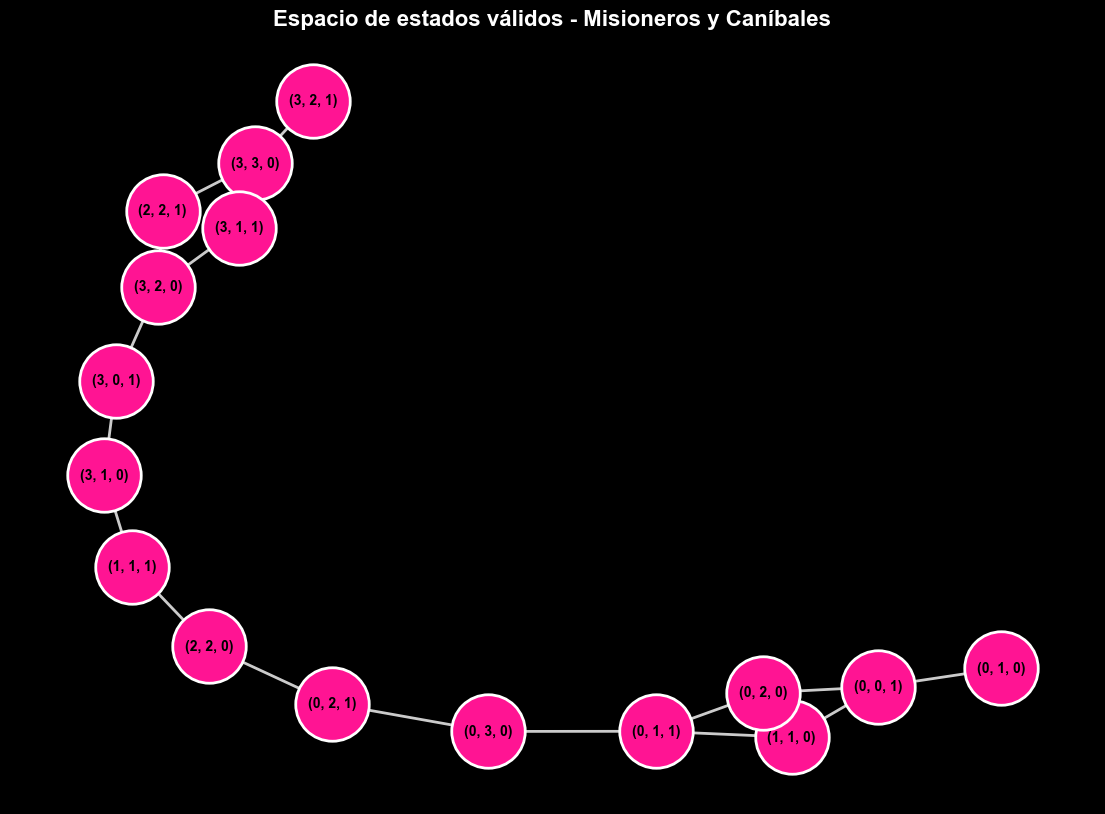

In [13]:
# ---------------------------------------------------------
# DIAGRAMA DEL ESPACIO DE ESTADOS VÁLIDOS
# ---------------------------------------------------------
# Construimos un grafo que contiene los estados válidos
# alcanzables desde el estado inicial.
# ---------------------------------------------------------

import networkx as nx
import matplotlib.pyplot as plt


# Creamos un grafo no dirigido para representar
# las conexiones entre los diferentes estados.
grafo_estados = nx.Graph()

# Utilizamos una cola para recorrer los estados
# alcanzables desde el estado inicial.
cola_estados = [estado_inicial_mc]

# Este conjunto permitirá evitar que un mismo estado
# sea procesado varias veces.
estados_visitados = {estado_inicial_mc}


# Recorremos todos los estados alcanzables.
while cola_estados:

    # Extraemos el primer estado pendiente.
    estado_actual = cola_estados.pop(0)

    # Agregamos el estado actual como nodo del grafo.
    grafo_estados.add_node(estado_actual)

    # Generamos todos sus sucesores válidos.
    sucesores = obtener_sucesores_mc(estado_actual)

    # Recorremos cada sucesor encontrado.
    for descripcion, nuevo_estado in sucesores:

        # Agregamos una conexión entre ambos estados.
        grafo_estados.add_edge(
            estado_actual,
            nuevo_estado
        )

        # Si todavía no habíamos visitado este estado,
        # lo agregamos a la cola para explorarlo después.
        if nuevo_estado not in estados_visitados:

            estados_visitados.add(nuevo_estado)
            cola_estados.append(nuevo_estado)


# ---------------------------------------------------------
# VISUALIZACIÓN DEL GRAFO
# ---------------------------------------------------------

# Definimos el tamaño de la figura.
plt.figure(figsize=(14, 10))

# Calculamos automáticamente una posición para cada nodo.
# seed=42 permite conservar la misma distribución
# cada vez que ejecutemos la celda.
posiciones = nx.spring_layout(
    grafo_estados,
    seed=42
)

# ---------------------------------------------------------
# DIBUJAR LAS CONEXIONES
# ---------------------------------------------------------

# Dibujamos primero las líneas que conectan los estados.
nx.draw_networkx_edges(
    grafo_estados,
    posiciones,
    width=2,
    edge_color="white",
    alpha=0.8
)

# ---------------------------------------------------------
# DIBUJAR LOS NODOS
# ---------------------------------------------------------

# Dibujamos los nodos en color rosa fluorescente.
# Aumentamos su tamaño para que las etiquetas
# puedan leerse con mayor facilidad.
nx.draw_networkx_nodes(
    grafo_estados,
    posiciones,
    node_size=2800,
    node_color="#FF1493",
    edgecolors="white",
    linewidths=2
)

# ---------------------------------------------------------
# DIBUJAR LAS ETIQUETAS
# ---------------------------------------------------------

# Colocamos dentro de cada nodo su estado correspondiente.
# Las etiquetas se muestran en negro y en negritas
# para mejorar su contraste con el rosa.
nx.draw_networkx_labels(
    grafo_estados,
    posiciones,
    font_size=10,
    font_color="black",
    font_weight="bold"
)

# ---------------------------------------------------------
# TÍTULO
# ---------------------------------------------------------

plt.title(
    "Espacio de estados válidos - Misioneros y Caníbales",
    fontsize=16,
    fontweight="bold"
)

# Eliminamos los ejes porque no representan
# ninguna magnitud en este grafo.
plt.axis("off")

# Mostramos el resultado.
plt.show()

## Parte B: Gato con Minimax y poda alfa-beta
## Constantes y tablero inicial

In [14]:
# ---------------------------------------------------------
# PARTE B: GATO (TRES EN RAYA)
# ---------------------------------------------------------
# Representaremos el tablero mediante una lista
# que contiene 9 posiciones.
#
# "X" -> jugador humano.
# "O" -> computadora.
# " " -> casilla vacía.
# ---------------------------------------------------------

# Símbolos que utilizaremos durante el juego.
JUGADOR = "X"
COMPUTADORA = "O"
VACIO = " "

# Creamos un tablero completamente vacío.
tablero_inicial = [
    VACIO, VACIO, VACIO,
    VACIO, VACIO, VACIO,
    VACIO, VACIO, VACIO
]

# Mostramos la representación interna.
print(tablero_inicial)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']


## Mostrar el tablero

In [15]:
# ---------------------------------------------------------
# VISUALIZACIÓN DEL TABLERO
# ---------------------------------------------------------
# Esta función recibe un tablero y lo muestra
# con la apariencia tradicional del juego de gato.
# ---------------------------------------------------------

def mostrar_tablero_gato(tablero):

    # Primera fila.
    print(
        f" {tablero[0]} | {tablero[1]} | {tablero[2]} "
    )

    print("---+---+---")

    # Segunda fila.
    print(
        f" {tablero[3]} | {tablero[4]} | {tablero[5]} "
    )

    print("---+---+---")

    # Tercera fila.
    print(
        f" {tablero[6]} | {tablero[7]} | {tablero[8]} "
    )

## Probar la visualización

In [16]:
# ---------------------------------------------------------
# PRUEBA DE VISUALIZACIÓN
# ---------------------------------------------------------
# Creamos temporalmente un tablero con algunas jugadas
# para comprobar que las posiciones se muestran
# correctamente.
# ---------------------------------------------------------

tablero_prueba = [
    "X", " ", "O",
    " ", "X", " ",
    " ", " ", "O"
]

mostrar_tablero_gato(tablero_prueba)

 X |   | O 
---+---+---
   | X |   
---+---+---
   |   | O 


## Mapa de posiciones para el jugador

### Posiciones del tablero

Para facilitar la interacción con el usuario, las casillas se numerarán del 1 al 9:

1 | 2 | 3<br>
--+---+--<br>
4 | 5 | 6<br>
--+---+--<br>
7 | 8 | 9

Internamente Python utiliza índices del 0 al 8, por lo que al recibir una jugada del usuario se convertirá la posición seleccionada a su índice correspondiente.

## Detectar un ganador

In [17]:
# ---------------------------------------------------------
# DETECCIÓN DE GANADOR
# ---------------------------------------------------------
# Esta función determina si un jugador consiguió
# colocar tres símbolos en línea.
#
# Recibe:
#   tablero -> estado actual del juego.
#   jugador -> símbolo que queremos comprobar ("X" u "O").
#
# Devuelve:
#   True  -> el jugador ganó.
#   False -> el jugador todavía no ha ganado.
# ---------------------------------------------------------

def hay_ganador(tablero, jugador):

    # Definimos todas las combinaciones de tres casillas
    # que producen una victoria.
    combinaciones_ganadoras = [
        (0, 1, 2),  # Primera fila.
        (3, 4, 5),  # Segunda fila.
        (6, 7, 8),  # Tercera fila.

        (0, 3, 6),  # Primera columna.
        (1, 4, 7),  # Segunda columna.
        (2, 5, 8),  # Tercera columna.

        (0, 4, 8),  # Diagonal principal.
        (2, 4, 6)   # Diagonal secundaria.
    ]

    # Revisamos cada combinación ganadora.
    for a, b, c in combinaciones_ganadoras:

        # Las tres posiciones deben contener
        # el símbolo del mismo jugador.
        if (
            tablero[a] == jugador
            and tablero[b] == jugador
            and tablero[c] == jugador
        ):
            return True

    # Si ninguna combinación produjo una victoria,
    # el jugador no ha ganado.
    return False

## Detectar tablero lleno

In [18]:
# ---------------------------------------------------------
# COMPROBACIÓN DE TABLERO LLENO
# ---------------------------------------------------------
# Devuelve True cuando ya no existe ninguna
# casilla vacía en el tablero.
# ---------------------------------------------------------

def tablero_lleno(tablero):

    # Si VACIO no aparece en el tablero,
    # significa que las nueve posiciones están ocupadas.
    return VACIO not in tablero

## Obtener movimientos disponibles

In [19]:
# ---------------------------------------------------------
# MOVIMIENTOS DISPONIBLES
# ---------------------------------------------------------
# Esta función devuelve los índices de todas
# las casillas que todavía están vacías.
# ---------------------------------------------------------

def obtener_movimientos_gato(tablero):

    # Creamos una lista donde guardaremos
    # las posiciones disponibles.
    movimientos = []

    # Recorremos las nueve posiciones.
    for posicion in range(9):

        # Si encontramos una casilla vacía,
        # guardamos su índice.
        if tablero[posicion] == VACIO:
            movimientos.append(posicion)

    # Devolvemos todas las posiciones disponibles.
    return movimientos

## Probar las tres funciones

In [20]:
# ---------------------------------------------------------
# PRUEBA DE LAS REGLAS DEL JUEGO
# ---------------------------------------------------------

# X tiene una combinación ganadora
# en la diagonal principal.
tablero_prueba_reglas = [
    "X", "O", " ",
    "O", "X", " ",
    " ", " ", "X"
]

# Mostramos el tablero.
mostrar_tablero_gato(tablero_prueba_reglas)

print("\nResultados de las comprobaciones:")

# Comprobamos si X ganó.
print(
    "¿X es ganador?",
    hay_ganador(tablero_prueba_reglas, "X")
)

# Comprobamos si O ganó.
print(
    "¿O es ganador?",
    hay_ganador(tablero_prueba_reglas, "O")
)

# Comprobamos si el tablero está lleno.
print(
    "¿El tablero está lleno?",
    tablero_lleno(tablero_prueba_reglas)
)

# Mostramos las posiciones internas disponibles.
print(
    "Índices disponibles:",
    obtener_movimientos_gato(tablero_prueba_reglas)
)

 X | O |   
---+---+---
 O | X |   
---+---+---
   |   | X 

Resultados de las comprobaciones:
¿X es ganador? True
¿O es ganador? False
¿El tablero está lleno? False
Índices disponibles: [2, 5, 6, 7]


## Contador de nodos

In [21]:
# ---------------------------------------------------------
# CONTADOR DE NODOS DE MINIMAX
# ---------------------------------------------------------
# Esta variable contará cuántos estados del juego
# son evaluados durante la búsqueda.
# ---------------------------------------------------------

nodos_minimax = 0

## Algoritmo Minimax

In [22]:

# ---------------------------------------------------------
# ALGORITMO MINIMAX
# ---------------------------------------------------------
# Esta función evalúa recursivamente los posibles estados
# futuros del juego.
#
# turno_max = True:
#     juega el humano (X) y busca MAXIMIZAR.
#
# turno_max = False:
#     juega la computadora (O) y busca MINIMIZAR.
#
# Valores:
#     +1 -> gana X (humano).
#      0 -> empate.
#     -1 -> gana O (computadora).
# ---------------------------------------------------------

def minimax(tablero, turno_max):

    # Utilizamos la variable global para contar
    # los nodos visitados durante la búsqueda.
    global nodos_minimax

    # Cada llamada representa un nodo visitado.
    nodos_minimax += 1

    # -----------------------------------------------------
    # CASOS TERMINALES
    # -----------------------------------------------------

    # Si gana X, devolvemos +1.
    if hay_ganador(tablero, JUGADOR):
        return 1

    # Si gana O, devolvemos -1.
    if hay_ganador(tablero, COMPUTADORA):
        return -1

    # Si el tablero está lleno y nadie ganó,
    # devolvemos 0 porque es un empate.
    if tablero_lleno(tablero):
        return 0

    # -----------------------------------------------------
    # TURNO DE MAX: JUGADOR HUMANO (X)
    # -----------------------------------------------------

    if turno_max:

        # Inicializamos con el menor valor posible.
        mejor_valor = -float("inf")

        # Recorremos las posiciones disponibles.
        for posicion in obtener_movimientos_gato(tablero):

            # Simulamos una jugada de X.
            tablero[posicion] = JUGADOR

            # El siguiente turno corresponde a O (MIN).
            valor = minimax(tablero, False)

            # Deshacemos la jugada simulada.
            tablero[posicion] = VACIO

            # MAX selecciona el valor mayor.
            mejor_valor = max(mejor_valor, valor)

        return mejor_valor

    # -----------------------------------------------------
    # TURNO DE MIN: COMPUTADORA (O)
    # -----------------------------------------------------

    else:

        # Inicializamos con el mayor valor posible.
        mejor_valor = float("inf")

        # Recorremos las posiciones disponibles.
        for posicion in obtener_movimientos_gato(tablero):

            # Simulamos una jugada de O.
            tablero[posicion] = COMPUTADORA

            # El siguiente turno corresponde a X (MAX).
            valor = minimax(tablero, True)

            # Deshacemos la jugada simulada.
            tablero[posicion] = VACIO

            # MIN selecciona el valor menor.
            mejor_valor = min(mejor_valor, valor)

        return mejor_valor


## Encontrar la mejor jugada

In [34]:

# ---------------------------------------------------------
# MEJOR JUGADA UTILIZANDO MINIMAX
# ---------------------------------------------------------
# Esta función prueba todas las jugadas disponibles
# para la computadora (O) y selecciona la mejor
# mediante el algoritmo Minimax.
#
# Convención:
# +1 -> gana X (humano).
#  0 -> empate.
# -1 -> gana O (computadora).
#
# Como O es MIN, buscamos el valor más pequeño.
# ---------------------------------------------------------

def mejor_jugada_minimax(tablero, buscar_victoria_inmediata=True):

    # Reiniciamos el contador para medir únicamente
    # los nodos visitados durante esta búsqueda.
    global nodos_minimax
    nodos_minimax = 0

    # La computadora minimiza, por lo que comenzamos
    # con un valor superior a cualquier resultado.
    mejor_valor = float("inf")

    # Guardaremos la posición de la mejor jugada.
    mejor_posicion = None

    # Esta optimización se utiliza durante el juego,
    # pero puede desactivarse para comparar algoritmos.
    if buscar_victoria_inmediata:

        for posicion in obtener_movimientos_gato(tablero):

            tablero[posicion] = COMPUTADORA

            victoria_inmediata = hay_ganador(
                tablero,
                COMPUTADORA
            )

            tablero[posicion] = VACIO

            if victoria_inmediata:
                return posicion, -1, 0

    # Probamos todas las posiciones disponibles.
    for posicion in obtener_movimientos_gato(tablero):

        # Simulamos temporalmente una jugada de O.
        tablero[posicion] = COMPUTADORA

        # Después de O juega X, que es MAX.
        valor = minimax(
            tablero,
            True
        )

        # Deshacemos la jugada simulada.
        tablero[posicion] = VACIO

        # Como la computadora es MIN,
        # conservamos el valor más pequeño.
        if valor < mejor_valor:

            mejor_valor = valor
            mejor_posicion = posicion

    # Devolvemos:
    # - Posición elegida.
    # - Valor de la jugada.
    # - Número de nodos visitados.
    return mejor_posicion, mejor_valor, nodos_minimax


## Primera prueba de Minimax

In [24]:
# ---------------------------------------------------------
# PRUEBA DE MINIMAX
# ---------------------------------------------------------

tablero_prueba_minimax = [
    "X", "X", " ",
    "O", "O", " ",
    " ", " ", " "
]

# Mostramos el tablero antes de buscar.
print("TABLERO ACTUAL")
print("--------------")
mostrar_tablero_gato(tablero_prueba_minimax)

# Buscamos la mejor jugada para O.
posicion, valor, nodos = mejor_jugada_minimax(
    tablero_prueba_minimax
)

print("\nRESULTADO DE MINIMAX")
print("--------------------")

# Sumamos 1 porque al usuario le mostramos
# posiciones del 1 al 9 y Python utiliza 0 al 8.
print("Mejor posición:", posicion + 1)

print("Valor de la jugada:", valor)
print("Nodos visitados:", nodos)

TABLERO ACTUAL
--------------
 X | X |   
---+---+---
 O | O |   
---+---+---
   |   |   

RESULTADO DE MINIMAX
--------------------
Mejor posición: 6
Valor de la jugada: -1
Nodos visitados: 0


## Contador para Alfa-Beta

In [25]:
# ---------------------------------------------------------
# CONTADOR DE NODOS DE ALFA-BETA
# ---------------------------------------------------------
# Este contador permitirá comparar cuántos estados
# visita Alfa-Beta respecto a Minimax tradicional.
# ---------------------------------------------------------

nodos_alfa_beta = 0

## Minimax con poda Alfa-Beta

In [26]:

# ---------------------------------------------------------
# MINIMAX CON PODA ALFA-BETA
# ---------------------------------------------------------
# Alfa-Beta obtiene la misma decisión óptima que Minimax,
# pero evita explorar ramas que no pueden mejorarla.
#
# Convención de utilidad:
# +1 -> gana X (humano).
#  0 -> empate.
# -1 -> gana O (computadora).
#
# turno_max = True:
#     juega X y busca MAXIMIZAR.
#
# turno_max = False:
#     juega O y busca MINIMIZAR.
#
# alfa:
#     mejor valor garantizado para MAX.
#
# beta:
#     mejor valor garantizado para MIN.
# ---------------------------------------------------------

def minimax_alfa_beta(tablero, turno_max, alfa, beta):

    # Utilizamos el contador global de Alfa-Beta.
    global nodos_alfa_beta

    # Cada llamada representa un nodo visitado.
    nodos_alfa_beta += 1

    # -----------------------------------------------------
    # CASOS TERMINALES
    # -----------------------------------------------------

    # Si gana X, devolvemos +1.
    if hay_ganador(tablero, JUGADOR):
        return 1

    # Si gana O, devolvemos -1.
    if hay_ganador(tablero, COMPUTADORA):
        return -1

    # Si nadie gana y el tablero está lleno,
    # devolvemos 0 porque es un empate.
    if tablero_lleno(tablero):
        return 0

    # -----------------------------------------------------
    # TURNO DE MAX: JUGADOR HUMANO (X)
    # -----------------------------------------------------

    if turno_max:

        # Inicializamos con el menor valor posible.
        mejor_valor = -float("inf")

        # Exploramos las casillas disponibles.
        for posicion in obtener_movimientos_gato(tablero):

            # Simulamos una jugada del humano X.
            tablero[posicion] = JUGADOR

            # Después juega la computadora O (MIN).
            valor = minimax_alfa_beta(
                tablero,
                False,
                alfa,
                beta
            )

            # Deshacemos la jugada simulada.
            tablero[posicion] = VACIO

            # MAX conserva el valor mayor.
            mejor_valor = max(
                mejor_valor,
                valor
            )

            # Actualizamos el mejor valor de MAX.
            alfa = max(
                alfa,
                mejor_valor
            )

            # Si alfa alcanza o supera beta,
            # podemos descartar el resto de la rama.
            if beta <= alfa:
                break

        return mejor_valor

    # -----------------------------------------------------
    # TURNO DE MIN: COMPUTADORA (O)
    # -----------------------------------------------------

    else:

        # Inicializamos con el mayor valor posible.
        mejor_valor = float("inf")

        # Exploramos las casillas disponibles.
        for posicion in obtener_movimientos_gato(tablero):

            # Simulamos una jugada de la computadora O.
            tablero[posicion] = COMPUTADORA

            # Después juega el humano X (MAX).
            valor = minimax_alfa_beta(
                tablero,
                True,
                alfa,
                beta
            )

            # Deshacemos la jugada simulada.
            tablero[posicion] = VACIO

            # MIN conserva el valor menor.
            mejor_valor = min(
                mejor_valor,
                valor
            )

            # Actualizamos el mejor valor de MIN.
            beta = min(
                beta,
                mejor_valor
            )

            # Si beta es menor o igual que alfa,
            # descartamos las ramas restantes.
            if beta <= alfa:
                break

        return mejor_valor


## Mejor jugada con Alfa-Beta

In [36]:

# ---------------------------------------------------------
# MEJOR JUGADA CON ALFA-BETA
# ---------------------------------------------------------
# Esta función evalúa las jugadas disponibles para
# la computadora (O) utilizando poda Alfa-Beta.
#
# Convención:
# +1 -> gana X (humano).
#  0 -> empate.
# -1 -> gana O (computadora).
#
# Como la computadora es MIN, buscamos el valor menor.
# ---------------------------------------------------------

def mejor_jugada_alfa_beta(tablero, buscar_victoria_inmediata=True):

    # Reiniciamos el contador de nodos visitados.
    global nodos_alfa_beta
    nodos_alfa_beta = 0

    # MIN comienza con el valor más alto posible.
    mejor_valor = float("inf")

    # Guardamos aquí la mejor posición encontrada.
    mejor_posicion = None

    # Alfa representa el mejor límite de MAX.
    alfa = -float("inf")

    # Beta representa el mejor límite de MIN.
    beta = float("inf")

    # Esta optimización se utiliza durante el juego,
    # pero puede desactivarse para comparar algoritmos.
    if buscar_victoria_inmediata:

        for posicion in obtener_movimientos_gato(tablero):

            tablero[posicion] = COMPUTADORA

            victoria_inmediata = hay_ganador(
                tablero,
                COMPUTADORA
            )

            tablero[posicion] = VACIO

            if victoria_inmediata:
                return posicion, -1, 0

    # Recorremos las casillas disponibles.
    for posicion in obtener_movimientos_gato(tablero):

        # Simulamos una jugada de la computadora O.
        tablero[posicion] = COMPUTADORA

        # Después de O juega X, que es MAX.
        valor = minimax_alfa_beta(
            tablero,
            True,
            alfa,
            beta
        )

        # Deshacemos la jugada simulada.
        tablero[posicion] = VACIO

        # MIN conserva el valor más pequeño.
        if valor < mejor_valor:

            mejor_valor = valor
            mejor_posicion = posicion

        # Actualizamos beta entre las alternativas
        # principales de la computadora.
        beta = min(
            beta,
            mejor_valor
        )

    # Devolvemos la posición seleccionada,
    # su valor y el número de nodos visitados.
    return (
        mejor_posicion,
        mejor_valor,
        nodos_alfa_beta
    )


## Comparar Minimax contra Alfa-Beta

In [28]:
# ---------------------------------------------------------
# COMPARACIÓN: MINIMAX VS. ALFA-BETA
# ---------------------------------------------------------

# Ejecutamos Minimax tradicional.
pos_minimax, valor_minimax, nodos_min = (
    mejor_jugada_minimax(tablero_prueba_minimax)
)

# Ejecutamos Minimax con poda Alfa-Beta.
pos_ab, valor_ab, nodos_ab = (
    mejor_jugada_alfa_beta(tablero_prueba_minimax)
)

print("COMPARACIÓN DE ALGORITMOS")
print("-------------------------")

print("\nMinimax:")
print("Mejor posición:", pos_minimax + 1)
print("Valor:", valor_minimax)
print("Nodos visitados:", nodos_min)

print("\nAlfa-Beta:")
print("Mejor posición:", pos_ab + 1)
print("Valor:", valor_ab)
print("Nodos visitados:", nodos_ab)

COMPARACIÓN DE ALGORITMOS
-------------------------

Minimax:
Mejor posición: 6
Valor: -1
Nodos visitados: 0

Alfa-Beta:
Mejor posición: 6
Valor: -1
Nodos visitados: 0


### Comparación de eficiencia: Minimax vs. Alfa-Beta

En esta segunda prueba se utilizará un tablero sin ganador y con varias casillas disponibles, para que ambos algoritmos tengan que explorar diferentes posibilidades.

El objetivo es comprobar que:

- Minimax y Alfa-Beta encuentran una jugada con la misma evaluación.
- Alfa-Beta puede reducir la cantidad de nodos explorados mediante la poda.
- Ambos algoritmos conservan el tablero original después de realizar sus simulaciones.

Se compararán la mejor posición, el valor de la jugada y los nodos visitados.

In [37]:

# ---------------------------------------------------------
# SEGUNDA COMPARACIÓN: EFICIENCIA DE MINIMAX Y ALFA-BETA
# ---------------------------------------------------------
# Utilizamos un tablero sin ganador para comparar
# la cantidad de nodos que explora cada algoritmo.
# ---------------------------------------------------------

# Creamos un tablero independiente para esta prueba.
tablero_eficiencia = [
    "X", " ", "O",
    " ", "X", " ",
    " ", " ", "O"
]

# Mostramos el tablero inicial.
print("TABLERO PARA COMPARAR EFICIENCIA")
print("--------------------------------")
mostrar_tablero_gato(tablero_eficiencia)

# Comprobamos que la partida todavía no terminó.
assert not hay_ganador(tablero_eficiencia, JUGADOR)
assert not hay_ganador(tablero_eficiencia, COMPUTADORA)
assert not tablero_lleno(tablero_eficiencia)

# Guardamos una copia para verificar que el tablero
# no sea modificado por los algoritmos.
tablero_original = tablero_eficiencia.copy()

# Ejecutamos Minimax tradicional.
pos_min, valor_min, nodos_min = mejor_jugada_minimax(
    tablero_eficiencia.copy(),
    buscar_victoria_inmediata=False
)

# Ejecutamos Minimax con poda Alfa-Beta.
pos_ab, valor_ab, nodos_ab = mejor_jugada_alfa_beta(
    tablero_eficiencia.copy(),
    buscar_victoria_inmediata=False
)

# Mostramos los resultados.
print("\nCOMPARACIÓN DE EFICIENCIA")
print("------------------------")

print("\nMinimax:")
print("Mejor posición:", pos_min + 1)
print("Valor:", valor_min)
print("Nodos visitados:", nodos_min)

print("\nAlfa-Beta:")
print("Mejor posición:", pos_ab + 1)
print("Valor:", valor_ab)
print("Nodos visitados:", nodos_ab)

# Comparamos los resultados obtenidos.
print("\nCOMPROBACIONES")
print("Misma evaluación:", valor_min == valor_ab)
print("Misma posición:", pos_min == pos_ab)
print("Tablero conservado:", tablero_eficiencia == tablero_original)

# Calculamos la reducción de nodos.
if nodos_min > 0:
    reduccion = (nodos_min - nodos_ab) / nodos_min * 100
    print(f"Reducción de nodos: {reduccion:.2f}%")

print("\nDIAGNÓSTICO DE FUNCIONES")
print("Función Minimax:", minimax.__code__.co_firstlineno)
print("Función Alfa-Beta:", minimax_alfa_beta.__code__.co_firstlineno)
print("Contador Minimax:", nodos_minimax)
print("Contador Alfa-Beta:", nodos_alfa_beta)

TABLERO PARA COMPARAR EFICIENCIA
--------------------------------
 X |   | O 
---+---+---
   | X |   
---+---+---
   |   | O 

COMPARACIÓN DE EFICIENCIA
------------------------

Minimax:
Mejor posición: 6
Valor: -1
Nodos visitados: 173

Alfa-Beta:
Mejor posición: 6
Valor: -1
Nodos visitados: 67

COMPROBACIONES
Misma evaluación: True
Misma posición: True
Tablero conservado: True
Reducción de nodos: 61.27%

DIAGNÓSTICO DE FUNCIONES
Función Minimax: 19
Función Alfa-Beta: 25
Contador Minimax: 173
Contador Alfa-Beta: 67


## Gráfica comparativa de eficiencia: Minimax vs. Alfa-Beta

Se comparan los nodos visitados por ambos algoritmos al evaluar el mismo tablero. La poda Alfa-Beta permite reducir la exploración de ramas sin modificar la evaluación de la jugada seleccionada.

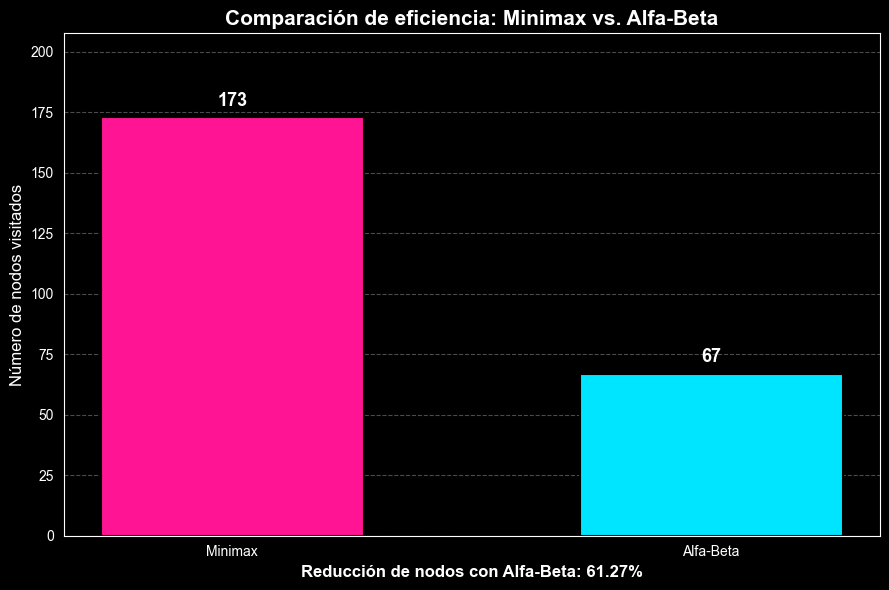

In [39]:
# ---------------------------------------------------------
# GRÁFICA COMPARATIVA DE EFICIENCIA
# MINIMAX VS. ALFA-BETA
# ---------------------------------------------------------

import matplotlib.pyplot as plt

# Recuperamos los resultados de la segunda comparación.
algoritmos = ["Minimax", "Alfa-Beta"]
nodos = [nodos_min, nodos_ab]

# Definimos los colores de las barras.
colores = ["#FF1493", "#00E5FF"]

# Creamos la figura.
plt.figure(figsize=(9, 6))

# Dibujamos las barras.
barras = plt.bar(
    algoritmos,
    nodos,
    color=colores,
    edgecolor="black",
    linewidth=1.5,
    width=0.55
)

# Mostramos la cantidad de nodos encima de cada barra.
for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 3,
        str(int(altura)),
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

# Agregamos título y etiquetas.
plt.title(
    "Comparación de eficiencia: Minimax vs. Alfa-Beta",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel(
    "Número de nodos visitados",
    fontsize=12
)

# Calculamos la reducción porcentual.
reduccion = (nodos_min - nodos_ab) / nodos_min * 100

# Mostramos la reducción debajo de la gráfica.
plt.xlabel(
    f"Reducción de nodos con Alfa-Beta: {reduccion:.2f}%",
    fontsize=12,
    fontweight="bold"
)

# Ajustamos los límites para mostrar las etiquetas.
plt.ylim(0, max(nodos) * 1.20)

# Desactivamos las líneas verticales de la cuadrícula.
plt.grid(axis="x", visible=False)

# Agregamos líneas horizontales de referencia.
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

# Ajustamos los espacios.
plt.tight_layout()

# Mostramos la gráfica.
plt.show()

## TERCERA COMPARACIÓN: MINIMAX Y ALFA-BETA DESDE EL TABLERO VACÍO

Se evalúa el desempeño de ambos algoritmos comenzando con las nueve casillas vacías, conforme a las instrucciones de la Práctica 6.

Para comparar la búsqueda recursiva, se desactiva la detección anticipada de victoria inmediata y se utilizan copias independientes del tablero.

In [43]:
# ---------------------------------------------------------
# TERCERA COMPARACIÓN: TABLERO VACÍO
# MINIMAX VS. ALFA-BETA
# ---------------------------------------------------------

# Creamos un tablero con las nueve casillas vacías.
tablero_vacio = [" "] * 9

# Guardamos una copia para comprobar que no se modifica.
tablero_original_vacio = tablero_vacio.copy()

print("TABLERO INICIAL VACÍO")

for fila in range(0, 9, 3):
    print(" " + " | ".join(tablero_vacio[fila:fila + 3]))
    if fila < 6:
        print("---+---+---")

# ---------------------------------------------------------
# EVALUACIÓN CON MINIMAX
# ---------------------------------------------------------

pos_min_vacio, valor_min_vacio, nodos_min_vacio = mejor_jugada_minimax(
    tablero_vacio.copy(),
    buscar_victoria_inmediata=False
)

# ---------------------------------------------------------
# EVALUACIÓN CON ALFA-BETA
# ---------------------------------------------------------

pos_ab_vacio, valor_ab_vacio, nodos_ab_vacio = mejor_jugada_alfa_beta(
    tablero_vacio.copy(),
    buscar_victoria_inmediata=False
)

# ---------------------------------------------------------
# RESULTADOS
# ---------------------------------------------------------

print("\nCOMPARACIÓN DESDE EL TABLERO VACÍO")

print("\nMinimax:")
print("Mejor posición:", pos_min_vacio)
print("Valor:", valor_min_vacio)
print("Nodos visitados:", nodos_min_vacio)

print("\nAlfa-Beta:")
print("Mejor posición:", pos_ab_vacio)
print("Valor:", valor_ab_vacio)
print("Nodos visitados:", nodos_ab_vacio)

# ---------------------------------------------------------
# COMPROBACIONES
# ---------------------------------------------------------

print("\nCOMPROBACIONES")

print("Misma evaluación:", valor_min_vacio == valor_ab_vacio)
print("Misma posición:", pos_min_vacio == pos_ab_vacio)
print("Tablero conservado:", tablero_vacio == tablero_original_vacio)

# Calculamos la reducción de nodos.
if nodos_min_vacio > 0:

    reduccion_vacio = (
        (nodos_min_vacio - nodos_ab_vacio)
        / nodos_min_vacio
    ) * 100

    print(f"Reducción de nodos: {reduccion_vacio:.2f}%")

TABLERO INICIAL VACÍO
   |   |  
---+---+---
   |   |  
---+---+---
   |   |  

COMPARACIÓN DESDE EL TABLERO VACÍO

Minimax:
Mejor posición: 0
Valor: 0
Nodos visitados: 549945

Alfa-Beta:
Mejor posición: 0
Valor: 0
Nodos visitados: 18296

COMPROBACIONES
Misma evaluación: True
Misma posición: True
Tablero conservado: True
Reducción de nodos: 96.67%


## Elección definitiva de la computadora
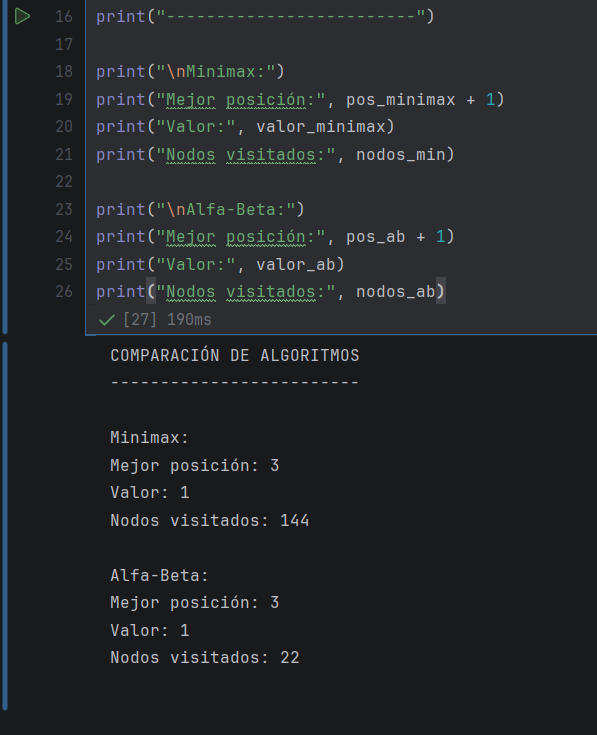

In [30]:
# ---------------------------------------------------------
# ELECCIÓN DE JUGADA DE LA COMPUTADORA
# ---------------------------------------------------------
# La computadora seguirá dos pasos:
#
# 1. Si puede ganar inmediatamente, realiza esa jugada.
# 2. Si no existe una victoria inmediata, utiliza
#    Minimax con poda Alfa-Beta.
# ---------------------------------------------------------

def elegir_jugada_computadora(tablero):

    # Recorremos todas las posiciones disponibles.
    for posicion in obtener_movimientos_gato(tablero):

        # Probamos temporalmente colocar O.
        tablero[posicion] = COMPUTADORA

        # Comprobamos si esa jugada produce
        # una victoria inmediata.
        if hay_ganador(tablero, COMPUTADORA):

            # Deshacemos la modificación antes
            # de devolver la posición.
            tablero[posicion] = VACIO

            return posicion

        # Si no ganó, deshacemos la jugada.
        tablero[posicion] = VACIO

    # -----------------------------------------------------
    # Si ninguna posición produce una victoria inmediata,
    # utilizamos Alfa-Beta para escoger la mejor jugada.
    # -----------------------------------------------------

    posicion, valor, nodos = mejor_jugada_alfa_beta(
        tablero
    )

    return posicion

## Prueba rápida

In [31]:
# ---------------------------------------------------------
# PRUEBA DE LA ELECCIÓN DE LA COMPUTADORA
# ---------------------------------------------------------

tablero_prueba_computadora = [
    "X", "X", " ",
    "O", "O", " ",
    " ", " ", " "
]

print("TABLERO ANTES DE LA JUGADA")
print("--------------------------")

mostrar_tablero_gato(tablero_prueba_computadora)

# Pedimos a la computadora su decisión.
jugada_computadora = elegir_jugada_computadora(
    tablero_prueba_computadora
)

print(
    "\nLa computadora elige la posición:",
    jugada_computadora + 1
)

TABLERO ANTES DE LA JUGADA
--------------------------
 X | X |   
---+---+---
 O | O |   
---+---+---
   |   |   

La computadora elige la posición: 6


## Juego completo humano contra computadora

In [32]:
# ---------------------------------------------------------
# JUEGO COMPLETO: HUMANO VS. COMPUTADORA
# ---------------------------------------------------------

def jugar_gato():

    # Creamos un tablero nuevo completamente vacío.
    tablero = [
        VACIO, VACIO, VACIO,
        VACIO, VACIO, VACIO,
        VACIO, VACIO, VACIO
    ]

    print("GATO: HUMANO VS. COMPUTADORA")
    print("-----------------------------")

    print("\nTú juegas con X.")
    print("La computadora juega con O.")

    print("\nPosiciones disponibles:")
    print(" 1 | 2 | 3 ")
    print("---+---+---")
    print(" 4 | 5 | 6 ")
    print("---+---+---")
    print(" 7 | 8 | 9 ")

    # El humano comenzará la partida.
    turno_jugador = True

    # El ciclo continúa hasta que exista
    # victoria o empate.
    while True:

        print("\nTablero actual:")
        mostrar_tablero_gato(tablero)

        # -------------------------------------------------
        # TURNO DEL JUGADOR
        # -------------------------------------------------

        if turno_jugador:

            while True:

                try:
                    # Solicitamos una posición del 1 al 9.
                    posicion = int(
                        input(
                            "\nElige una posición (1-9): "
                        )
                    )

                    # Convertimos la posición del usuario
                    # al índice interno de Python.
                    indice = posicion - 1

                    # Comprobamos que esté entre 1 y 9.
                    if posicion < 1 or posicion > 9:
                        print(
                            "La posición debe estar entre 1 y 9."
                        )
                        continue

                    # Comprobamos que la casilla esté libre.
                    if tablero[indice] != VACIO:
                        print(
                            "Esa casilla ya está ocupada."
                        )
                        continue

                    # La jugada es válida.
                    break

                # Si el usuario escribe algo que no sea
                # un número entero, evitamos que el
                # programa termine con un error.
                except ValueError:
                    print(
                        "Debes escribir un número del 1 al 9."
                    )

            # Colocamos la X.
            tablero[indice] = JUGADOR

            # Comprobamos si el humano ganó.
            if hay_ganador(tablero, JUGADOR):

                print("\nTABLERO FINAL")
                mostrar_tablero_gato(tablero)

                print("\n¡Ganaste!")
                break

        # -------------------------------------------------
        # TURNO DE LA COMPUTADORA
        # -------------------------------------------------

        else:

            print("\nLa computadora está pensando...")

            # La computadora obtiene su mejor jugada.
            posicion_computadora = (
                elegir_jugada_computadora(tablero)
            )

            # Colocamos O en el tablero.
            tablero[posicion_computadora] = COMPUTADORA

            print(
                "La computadora eligió la posición:",
                posicion_computadora + 1
            )

            # Comprobamos si ganó la computadora.
            if hay_ganador(tablero, COMPUTADORA):

                print("\nTABLERO FINAL")
                mostrar_tablero_gato(tablero)

                print("\nLa computadora ganó.")
                break

        # -------------------------------------------------
        # COMPROBACIÓN DE EMPATE
        # -------------------------------------------------

        # Si nadie ganó y ya no quedan casillas,
        # la partida termina en empate.
        if tablero_lleno(tablero):

            print("\nTABLERO FINAL")
            mostrar_tablero_gato(tablero)

            print("\nLa partida terminó en empate.")
            break

        # Cambiamos el turno.
        turno_jugador = not turno_jugador

## Iniciar una partida

In [40]:
# ---------------------------------------------------------
# INICIAR EL JUEGO
# ---------------------------------------------------------

jugar_gato()

GATO: HUMANO VS. COMPUTADORA
-----------------------------

Tú juegas con X.
La computadora juega con O.

Posiciones disponibles:
 1 | 2 | 3 
---+---+---
 4 | 5 | 6 
---+---+---
 7 | 8 | 9 

Tablero actual:
   |   |   
---+---+---
   |   |   
---+---+---
   |   |   

Tablero actual:
   |   |   
---+---+---
   | X |   
---+---+---
   |   |   

La computadora está pensando...
La computadora eligió la posición: 1

Tablero actual:
 O |   |   
---+---+---
   | X |   
---+---+---
   |   |   

Tablero actual:
 O | X |   
---+---+---
   | X |   
---+---+---
   |   |   

La computadora está pensando...
La computadora eligió la posición: 8

Tablero actual:
 O | X |   
---+---+---
   | X |   
---+---+---
   | O |   

Tablero actual:
 O | X |   
---+---+---
   | X |   
---+---+---
   | O | X 

La computadora está pensando...
La computadora eligió la posición: 3

Tablero actual:
 O | X | O 
---+---+---
   | X |   
---+---+---
   | O | X 

Tablero actual:
 O | X | O 
---+---+---
   | X | X 
---+---+

## Resultados y conclusiones

### Parte A. Misioneros y caníbales mediante BFS

Se implementó el algoritmo de búsqueda en anchura (BFS) para resolver el problema de los tres misioneros y tres caníbales, considerando las restricciones de seguridad en ambas orillas del río y la capacidad máxima de dos pasajeros en la barca.

**Resultados obtenidos:**

- Estado inicial: (3, 3, 0).
- Estado objetivo: (0, 0, 1).
- Número de cruces: 11.
- Nodos expandidos: 14.

El algoritmo encontró una secuencia válida de 11 cruces que permite trasladar a todos los personajes a la orilla derecha sin incumplir las restricciones establecidas.

Se generó también un grafo para representar visualmente los estados válidos alcanzables y sus conexiones.

### Parte B. Juego de gato mediante Minimax y poda Alfa-Beta

Se implementaron los algoritmos Minimax y Minimax con poda Alfa-Beta para evaluar posibles jugadas en el juego de gato (tres en raya).

En la segunda prueba de eficiencia, ambos algoritmos seleccionaron la posición 6 y obtuvieron una evaluación de -1, correspondiente a una victoria de la computadora según la convención utilizada.

**Resultados de la comparación:**

- Minimax tradicional: 173 nodos visitados.
- Minimax con poda Alfa-Beta: 67 nodos visitados.
- Reducción de nodos: 61.27 %.
- Coincidencia de evaluación: verdadera.
- Coincidencia de posición: verdadera.
- Conservación del tablero original: verdadera.

Estos resultados muestran que la poda Alfa-Beta permitió reducir la cantidad de estados explorados sin modificar la decisión obtenida por Minimax.

La comparación se realizó desactivando la detección anticipada de victoria inmediata, para medir el trabajo de búsqueda recursiva de ambos algoritmos.

### Conclusión general

Esta práctica permitió comprender y aplicar diferentes estrategias de búsqueda utilizadas en Inteligencia Artificial.

En el problema de misioneros y caníbales, BFS permitió encontrar una solución con el mínimo número de cruces bajo las reglas establecidas.

En el juego de gato, Minimax permitió evaluar las posibles decisiones considerando las respuestas del adversario, mientras que la poda Alfa-Beta optimizó la exploración al descartar ramas que no podían mejorar la decisión final.

Se concluye que la elección del algoritmo y la aplicación de técnicas de optimización influyen directamente en la eficiencia de la búsqueda, aunque no necesariamente modifican la solución obtenida.